# Setup

In [31]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random

In [7]:
DATASET_ROOT = os.path.join("..", "data", "raw", "SUNRGBD_local") 

TRAIN_DIR  = os.path.join(DATASET_ROOT, "train")
TEST_DIR   = os.path.join(DATASET_ROOT, "test")

RGB_TRAIN = os.path.join(TRAIN_DIR, "rgb")
MASK_TRAIN = os.path.join(TRAIN_DIR, "mask")
DEPTH_TRAIN = os.path.join(TRAIN_DIR, "depth")

RGB_TEST = os.path.join(TEST_DIR, "rgb")
MASK_TEST = os.path.join(TEST_DIR, "mask")
DEPTH_TEST = os.path.join(TEST_DIR, "depth")

In [10]:
# Get all RGB filenames (they match the mask filenames exactly)
train_filenames = [os.path.basename(f) for f in glob.glob(os.path.join(RGB_TRAIN, "*.jpg"))]
print(f"Total training images found: {len(train_filenames)}")

Total training images found: 5285


In [13]:
# Based on the script utils/download_sunrgbd.py: 0=background, 1=wall, 2=floor, 3=ceiling, 4=window, 5=door
CLASS_MAPPING = {
    0: "Background",
    1: "Wall",
    2: "Floor",
    3: "Ceiling",
    4: "Window",
    5: "Door"
}
# Colors: Black, Red, Green, Blue, Yellow, Magenta
COLORS = [(0,0,0), (255,0,0), (0,255,0), (0,0,255), (255,255,0), (255,0,255)]

# Load samples

In [14]:
def load_sample(filename):
    rgb_path = os.path.join(RGB_TRAIN, filename)
    mask_path = os.path.join(MASK_TRAIN, filename.replace(".jpg", ".png"))
    
    image = cv2.imread(rgb_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    return image, mask

def visualize_sample(filename):
    image, mask = load_sample(filename)
    
    # Create colored mask
    colored_mask = np.zeros_like(image)
    for class_id, color in zip(CLASS_MAPPING.keys(), COLORS):
        colored_mask[mask == class_id] = color

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(image)
    axes[0].set_title(f"RGB Image: {filename}")
    axes[0].axis('off')

    axes[1].imshow(mask, cmap='jet') 
    axes[1].set_title("Raw Mask (IDs 0-5)")
    axes[1].axis('off')

    axes[2].imshow(colored_mask)
    axes[2].set_title("Colored Mask Overlay")
    axes[2].axis('off')
    plt.show()



--- Visualizing 3 Random Samples ---


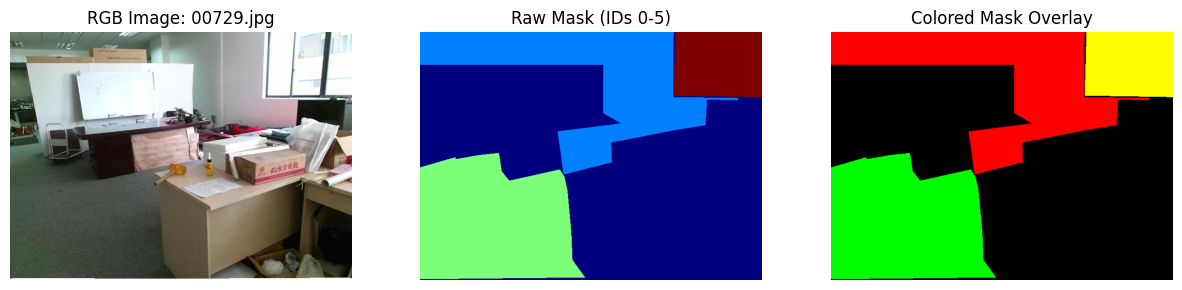

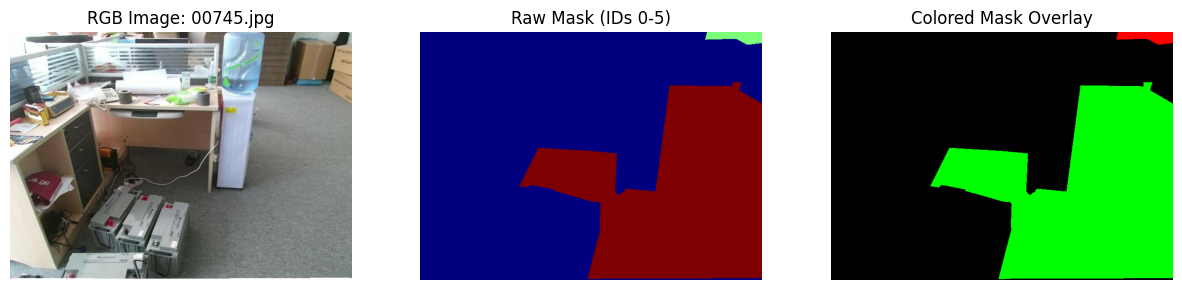

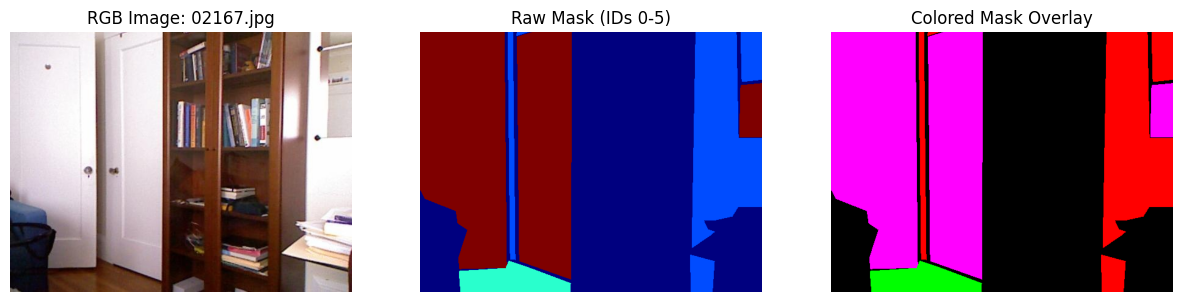

In [30]:
print("\n--- Visualizing 3 Random Samples ---")
for fname in random.sample(train_filenames, 3):
    visualize_sample(fname)

# Data distribution

In [51]:
print("Number of training images:", len(train_filenames))
print("Number of test images:", len(glob.glob(os.path.join(RGB_TEST, "*.jpg"))))

Number of training images: 5285
Number of test images: 5050


In [22]:
def calculate_distribution(filenames, sample_size=200):
    all_pixel_counts = {}
    image_counts = {i: 0 for i in range(6)}
    
    sampled_filenames = random.sample(filenames, min(sample_size, len(filenames)))
    
    for fname in sampled_filenames:
        _, mask = load_sample(fname)
        if mask is None: continue
            
        unique, counts = np.unique(mask, return_counts=True)
        for class_id, count in zip(unique, counts):
            if class_id in all_pixel_counts:
                all_pixel_counts[class_id] += count
            else:
                all_pixel_counts[class_id] = count
                
            # Count how many images contain this class
            if class_id in image_counts:
                image_counts[class_id] += 1
                
    df_dist = pd.DataFrame(list(all_pixel_counts.items()), columns=['Class_ID', 'Total_Pixels'])
    df_dist['Pixel_Percentage'] = (df_dist['Total_Pixels'] / df_dist['Total_Pixels'].sum()) * 100
    df_dist['Class_Name'] = df_dist['Class_ID'].map(CLASS_MAPPING)
    
    # Add image counts
    df_dist['Image_Count'] = df_dist['Class_ID'].map(image_counts)
    df_dist['Image_Percentage'] = (df_dist['Image_Count'] / len(sampled_filenames)) * 100
    
    return df_dist.sort_values(by='Class_ID')

In [27]:
print("Class Distribution (sampled 1000 images)")
dist_df = calculate_distribution(train_filenames, sample_size=1000)
print(dist_df.to_string(index=False))

Class Distribution (sampled 1000 images)
 Class_ID  Total_Pixels  Pixel_Percentage Class_Name  Image_Count  Image_Percentage
        0     178151257         56.383554 Background         1000             100.0
        1      65615622         20.766859       Wall          922              92.2
        2      55494447         17.563582      Floor          856              85.6
        3       2649046          0.838403    Ceiling          124              12.4
        4       7639516          2.417850     Window          272              27.2
        5       6413270          2.029752       Door          244              24.4


one of the outputs:

```
Class Distribution (sampled 1000 images)
 Class_ID  Total_Pixels  Pixel_Percentage Class_Name  Image_Count  Image_Percentage
        0     176883505         56.975842 Background         1000             100.0
        1      61906148         19.940553       Wall          917              91.7
        2      55104074         17.749541      Floor          875              87.5
        3       2424018          0.780799    Ceiling          134              13.4
        4       7639612          2.460791     Window          298              29.8
        5       6496161          2.092475       Door          244              24.4
```

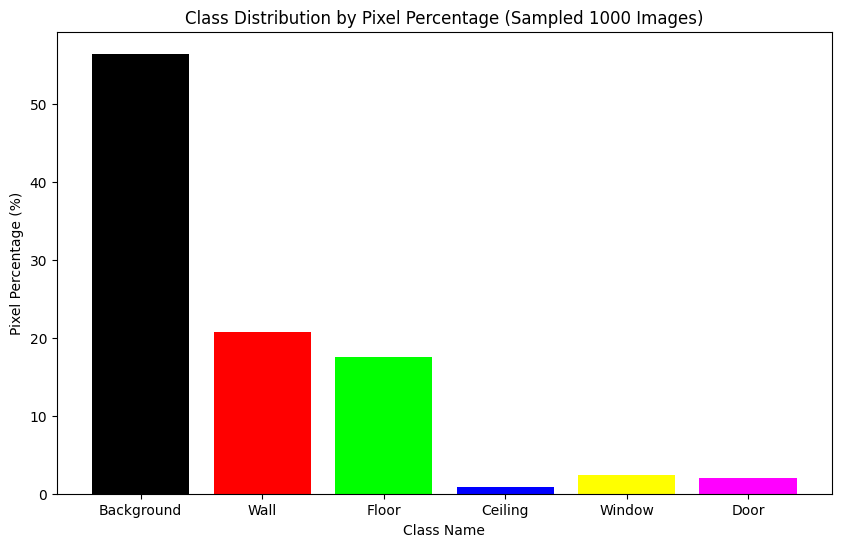

In [28]:
# plotting the distribution
plt.figure(figsize=(10, 6))
plt.bar(dist_df['Class_Name'], dist_df['Pixel_Percentage'], color=[np.array(color)/255 for color in COLORS])
plt.title("Class Distribution by Pixel Percentage (Sampled 1000 Images)")
plt.xlabel("Class Name")
plt.ylabel("Pixel Percentage (%)")
plt.show()

In [52]:
CLASS_MAPPING = {
    0: "Background",
    1: "Wall",
    2: "Floor",
    3: "Ceiling",
    4: "Window",
    5: "Door"
}

def load_sample_sun(filename):
    """Loads a SUN RGB-D image and mask from local directories."""
    rgb_path = os.path.join(RGB_TRAIN, filename)
    # The mask is a .png, while the image is a .jpg
    mask_path = os.path.join(MASK_TRAIN, filename.replace(".jpg", ".png"))
    
    image = cv2.imread(rgb_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    return image, mask

def deduce_class_mapping_sun(filename):
    image, mask = load_sample_sun(filename)
    if image is None:
        print(f"Could not load {filename}")
        return

    # We know we have 6 classes (0 through 5)
    total_plots = 7  # 1 original + 6 classes
    
    # Create a 2x4 grid (8 slots, which is perfect for 7 plots)
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    axes = axes.flatten() 

    # Plot the original image first
    axes[0].imshow(image)
    axes[0].set_title("Original RGB")
    axes[0].axis('off')

    # Loop through each class ID
    for class_id in range(6):
        # Create a copy of the image
        overlay = image.copy()
        
        # Create a boolean mask for this specific class
        class_mask = (mask == class_id)
        
        # Color the class pixels RED (255, 0, 0) so they stand out
        overlay[class_mask] = [255, 0, 0] 
        
        # Plot at index class_id + 1 (since 0 is the original image)
        axes[class_id + 1].imshow(overlay)
        axes[class_id + 1].set_title(f"Class {class_id}: {CLASS_MAPPING[class_id]}")
        axes[class_id + 1].axis('off')

    # Hide the 8th empty subplot
    axes[7].axis('off')

    plt.tight_layout()
    plt.show()

Deducing Class Mapping visually for SUN RGB-D...


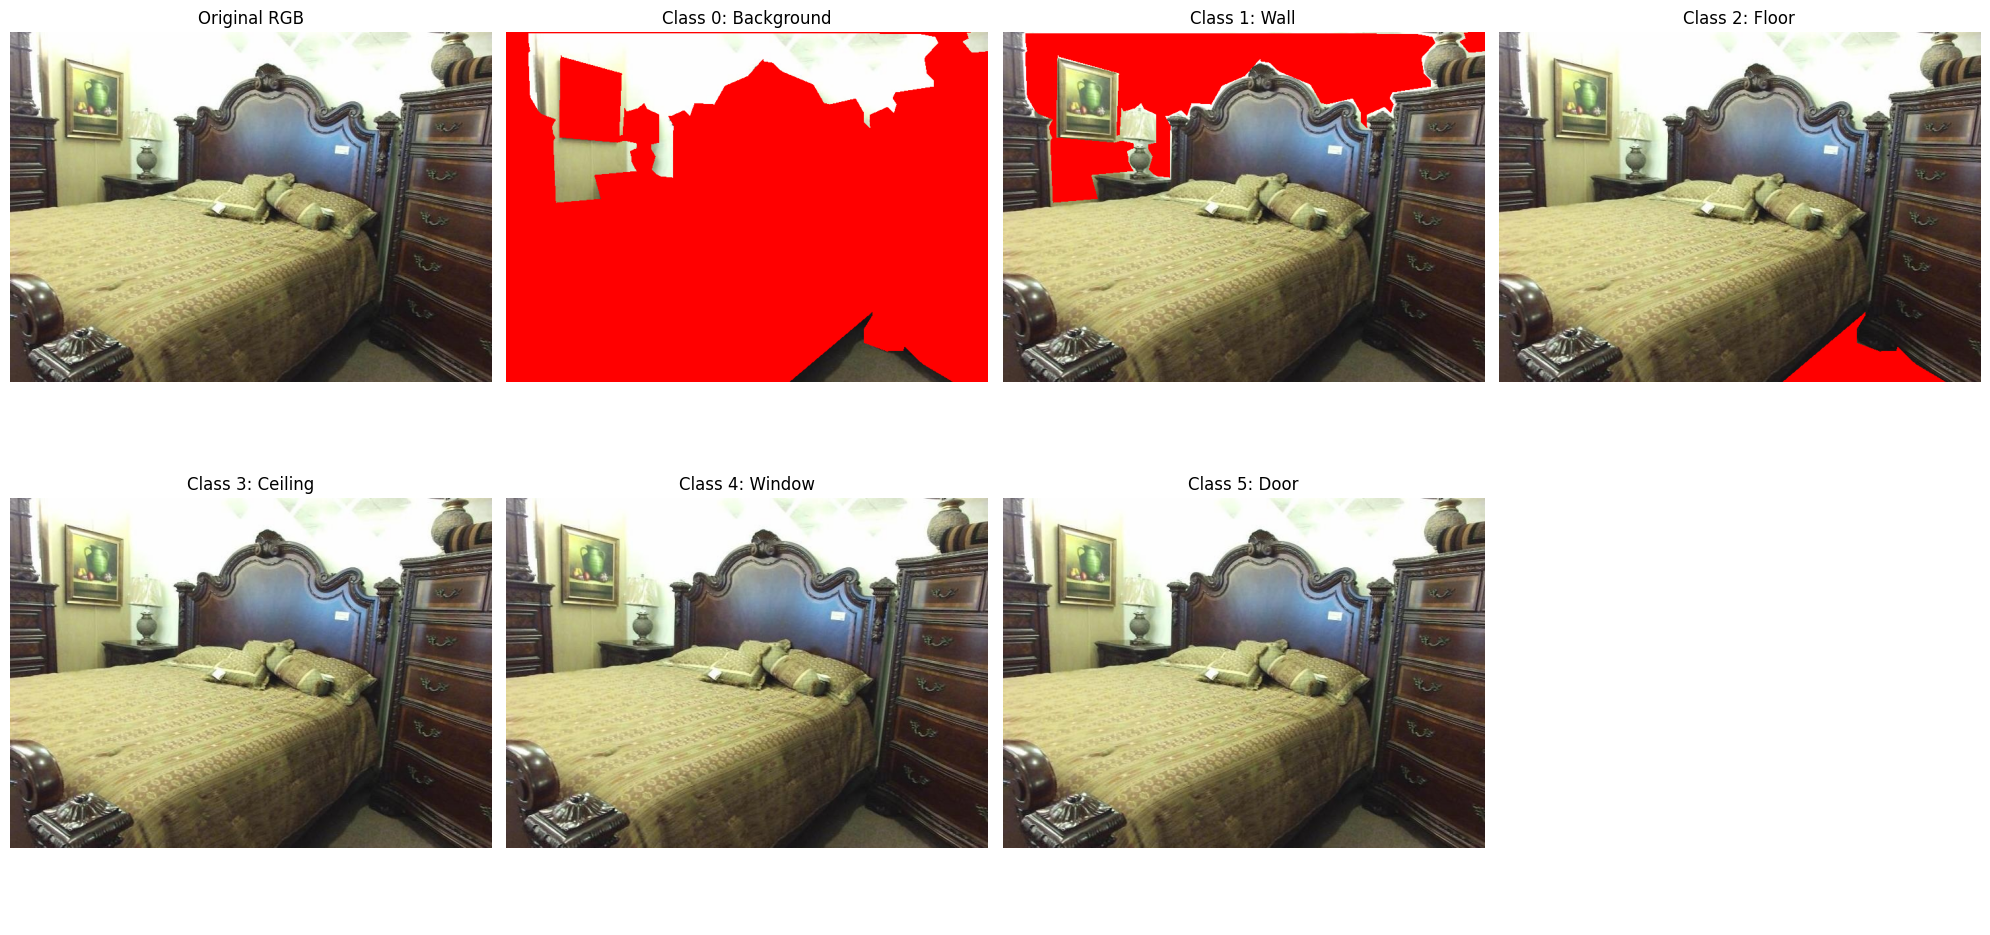

In [49]:
# random sample
print("Deducing Class Mapping visually for SUN RGB-D...")
deduce_class_mapping_sun("00020.jpg") 

* good, it didn't find a window because there isn't any

Deducing Class Mapping visually for SUN RGB-D...
Found a sample with a window: 00000.jpg


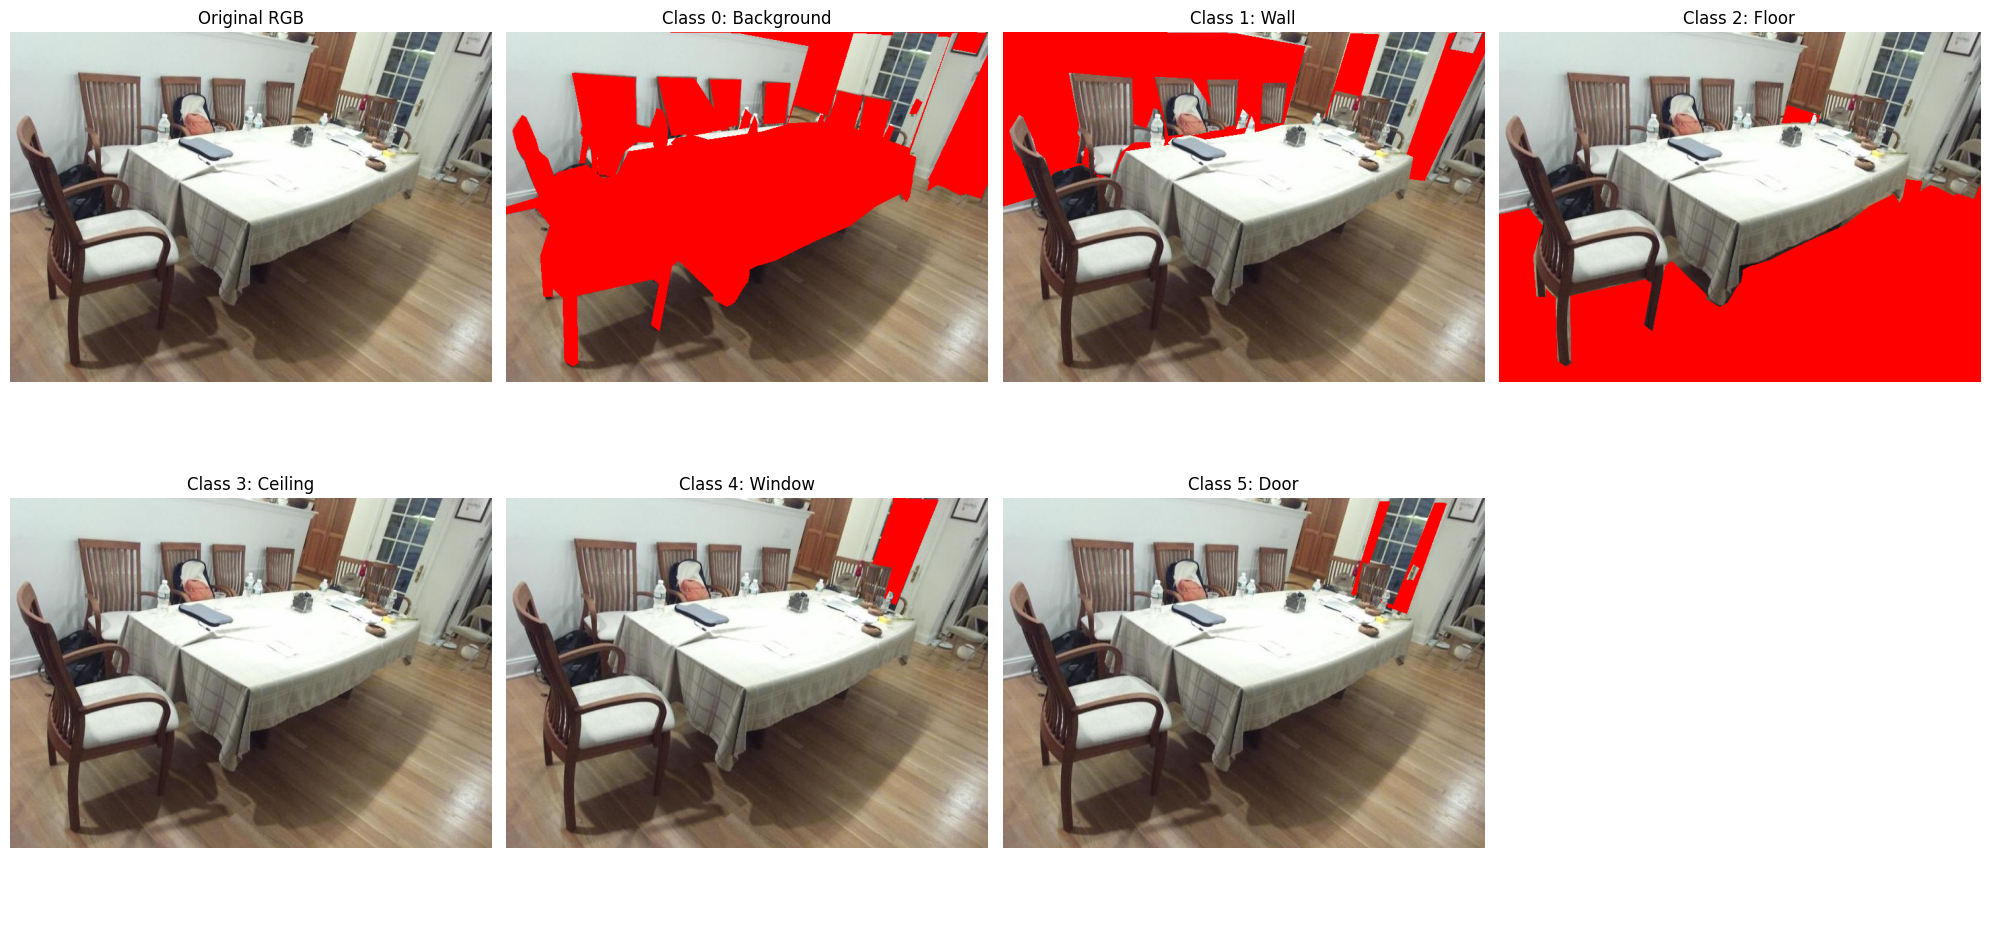

In [50]:
# now let's find the first image that contains a window (class ID 4) and visualize it
print("Deducing Class Mapping visually for SUN RGB-D...")
# find a file that has a window in it by searching
for filename in glob.glob(os.path.join(RGB_TRAIN, "*.jpg")):
    image, mask = load_sample_sun(os.path.basename(filename))
    if image is not None and mask is not None:
        if 4 in np.unique(mask):  # Check if class ID 4 (Window) is present
            print(f"Found a sample with a window: {os.path.basename(filename)}")
            break

deduce_class_mapping_sun(os.path.basename(filename))

* it treats the glass panes of the door as window which is good because this is exactly what we need